#Experiment 4: Hill climbing

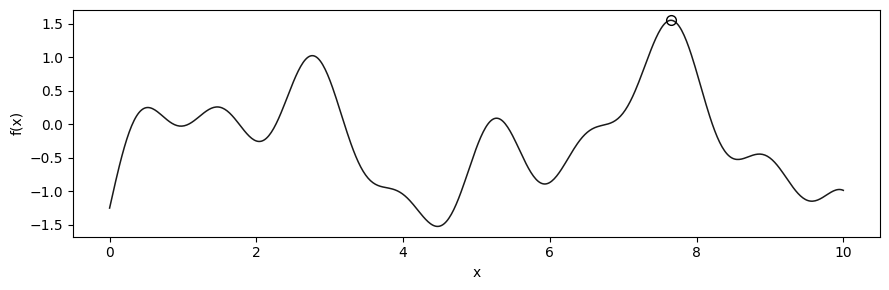

In [10]:
import numpy as np, matplotlib.pyplot as plt

xs = np.linspace(0, 10, 600)
fx = np.sin(xs) + 0.6*np.sin(2.7*xs) + 0.35*np.sin(5.1*xs) - 0.05*(xs-5)**2
plt.figure(figsize=(9, 3))
plt.plot(xs, fx, lw=1.1, color='0.1')
plt.plot(xs[np.argmax(fx)], fx.max(), 'o', ms=7, mfc='none', mec='k')
plt.xlabel('x'); plt.ylabel('f(x)'); plt.tight_layout(); plt.show()


In [17]:
import random


def conflicts(board):  # from Experiment 2
    n = len(board); bad = 0
    for i in range(n):
        for j in range(i+1, n):
            if board[i] == board[j] or abs(board[i]-board[j]) == abs(i-j):
                bad += 1
    return bad


def hill_climb(n=8, seed=0):
    """Steepest ascent. Returns True if a conflict-free board is reached."""
    r = random.Random(seed)
    board = [r.randrange(n) for _ in range(n)]  # a complete, random board

    while True:
        current = conflicts(board)

        if current == 0:
            return True  # solved

        best, move = current, None

        for c in range(n):  # try every single-queen move
            old = board[c]

            for row in range(n):
                if row == old:
                    continue

                board[c] = row
                v = conflicts(board)

                if v < best:
                    best, move = v, (c, row)

            board[c] = old

        if move is None:
            return False  # local minimum: stuck

        board[move[0]] = move[1]

In [23]:
def hill_climb_restarts(n=8, restarts=50, seed=0):
    for k in range(restarts):
        if hill_climb(n, seed=seed*1000 + k):
            return True
    return False


trials = 200
plain = sum(hill_climb(8, seed=s) for s in range(trials)) / trials
print(f'plain hill climbing: {100*plain:.1f}% of {trials} random starts')


for k in (1, 2, 5, 10, 20):
    ok = sum(hill_climb_restarts(8, k, seed=1000+s) for s in range(trials)) / trials
    print(f'{k:>3} restarts: {100*ok:.5f}%')

plain hill climbing: 12.5% of 200 random starts
  1 restarts: 14.50000%
  2 restarts: 25.50000%
  5 restarts: 56.00000%
 10 restarts: 78.00000%
 20 restarts: 97.50000%
